In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score
from data_utils import FEATURES

windows = pd.read_csv("data_features/windows_5m.csv")
windows = windows[windows["label"] != "left out"].copy()
windows["is_bump"] = (windows["label"] == "bump").astype(int)

roads = list(windows["road"].unique())

print("Windows:", len(windows))
print("Roads:", roads)
print("Features:", FEATURES)

Windows: 2721
Roads: ['Iisingintie', 'Kaittiaisentie', 'sinetänsalmentie']
Features: ['GyrY_std', 'AccZ_std', 'GyrX_std', 'GyrZ_std', 'AccY_std', 'AccX_std', 'Pitch_std', 'speed']


In [3]:
def evaluate(true, pred):
    found = ((true == 1) & (pred == 1)).sum()
    missed = ((true == 1) & (pred == 0)).sum()
    false_alarms = ((true == 0) & (pred == 1)).sum()

    if found + missed > 0:
        recall = found / (found + missed)
    else:
        recall = 0

    if found + false_alarms > 0:
        precision = found / (found + false_alarms)
    else:
        precision = 0

    if precision + recall > 0:
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = 0

    return {"found": found, "missed": missed, "false_alarms": false_alarms,
            "recall": recall, "precision": precision, "f1": f1}

In [4]:
# support variables and target
X = windows[FEATURES]
y = windows["is_bump"]

categories = ["no bump", "bump"]

In [5]:
# Split the data into training and test sets based on road
test_road = "Kaittiaisentie"

train_rows = windows["road"] != test_road
test_rows = windows["road"] == test_road

X_train = X[train_rows]
X_test = X[test_rows]
y_train = y[train_rows]
y_test = y[test_rows]

print("Training windows:", len(X_train), "| bumps:", y_train.sum())
print("Test windows:", len(X_test), "| bumps:", y_test.sum())

Training windows: 2107 | bumps: 488
Test windows: 614 | bumps: 30


In [6]:
# Train a random forest classifier
model = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=101)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",101
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1

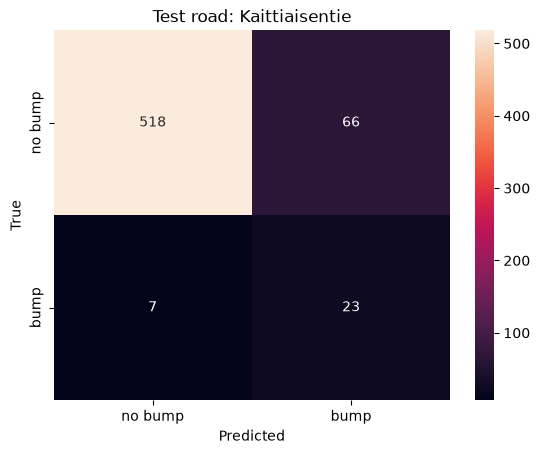

              precision    recall  f1-score   support

     no bump       0.99      0.89      0.93       584
        bump       0.26      0.77      0.39        30

    accuracy                           0.88       614
   macro avg       0.62      0.83      0.66       614
weighted avg       0.95      0.88      0.91       614

Model overall accuracy: 88.11%
ROC-AUC (test road only): 0.875


In [7]:
# Evaluate the model on the test set
test_predictions = model.predict(X_test)

sns.heatmap(confusion_matrix(y_test, test_predictions), annot=True, fmt="g",
            xticklabels=categories, yticklabels=categories)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(f"Test road: {test_road}")
plt.show()

print(classification_report(y_test, test_predictions, target_names=categories))

acc = accuracy_score(y_test, test_predictions)
print("Model overall accuracy: {:.2f}%".format(acc * 100))

test_probabilities = model.predict_proba(X_test)[:, 1]
print("ROC-AUC (test road only):", round(roc_auc_score(y_test, test_probabilities), 3))

* The model finds most bumps, but raises a lot of false alarms.

#### All three test roads in one go

**The idea behind the splitting**

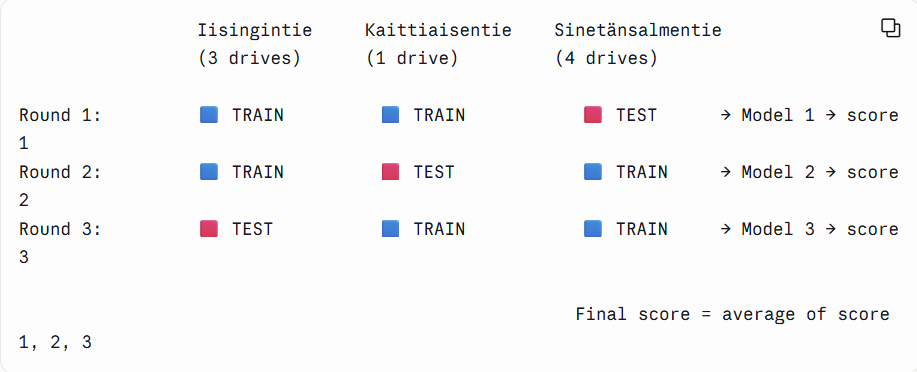

In [8]:
# Cross-validation: train on two roads, test on the third
results = []

for test_road in roads:
    # 1. split: this road = test, the other two = training
    train_rows = windows["road"] != test_road
    test_rows = windows["road"] == test_road
    X_train = X[train_rows]
    X_test = X[test_rows]
    y_train = y[train_rows]
    y_test = y[test_rows]

    # 2. train a fresh model
    model = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=101)
    model.fit(X_train, y_train)

    # 3. predict on the test road
    test_predictions = model.predict(X_test)
    test_probabilities = model.predict_proba(X_test)[:, 1]

    # 4. score and remember the result
    scores = evaluate(y_test, test_predictions)
    scores["road"] = test_road
    scores["roc_auc"] = roc_auc_score(y_test, test_probabilities)
    results.append(scores)

results = pd.DataFrame(results).set_index("road").round(2)
print(results)
print()
print("Average over the three roads:")
print(results[["recall", "precision", "f1", "roc_auc"]].mean().round(2))

                  found  missed  false_alarms  recall  precision    f1  \
road                                                                     
Iisingintie         189     159           501    0.54       0.27  0.36   
Kaittiaisentie       23       7            66    0.77       0.26  0.39   
sinetänsalmentie     55      85             8    0.39       0.87  0.54   

                  roc_auc  
road                       
Iisingintie          0.67  
Kaittiaisentie       0.87  
sinetänsalmentie     0.64  

Average over the three roads:
recall       0.57
precision    0.47
f1           0.43
roc_auc      0.73
dtype: float64


* Too eager on one road, too cautious on another. The model is confused by differences between roads and drives, not by the bumps themselves

* The suspects can be speed and roughness. For eg, what the model learned when Iisingintie was the test road. It trained only on Kaittiaisentie (driven at about 41 km/h) and Sinetänsalmentie (about 40–72 km/h). It never saw a drive at 80 km/h. Then it’s tested on Iisingintie, which includes the 80 km/h drive. At 80 km/h, all shaking is bigger, even on normal road (remember the exploration: 3× more variation at higher speed). So the model sees big numbers everywhere and shouts “bump!”

* The likely fix is to make the features relative: instead of “GyrY varies by 0.04 here,” use “GyrY varies 2.5× more than usual on this drive.” That removes the effect of speed and of how rough the road generally is, and keeps only what makes a bump special: more shaking than its surroundings.

### Let's solve the first problem first

#### Are the false alarms mostly from the fast drive?

In [9]:
test_road = "Iisingintie"
train_rows = windows["road"] != test_road
test_rows = windows["road"] == test_road

model = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=101)
model.fit(X[train_rows], y[train_rows])

test = windows[test_rows].copy()
test["pred"] = model.predict(X[test_rows])

for drive, g in test.groupby("drive"):
    normal = (g["is_bump"] == 0).sum()
    false_alarms = ((g["is_bump"] == 0) & (g["pred"] == 1)).sum()
    speed_kmh = round(g["speed"].mean() * 3.6)
    print(drive.split("_")[2], "|", speed_kmh, "km/h | false alarms:", false_alarms, "of", normal, "normal windows")

m800 | 77 km/h | false alarms: 349 of 476 normal windows
m801 | 59 km/h | false alarms: 139 of 489 normal windows
m802 | 39 km/h | false alarms: 13 of 492 normal windows


#### The fix: relative features

* The idea: a bump isn’t “a lot of shaking.” It’s more shaking than usual on this drive. So for every drive, we measure its calm level (how much it normally shakes), and divide each window’s value by it:

relative GyrY_std = window's GyrY_std ÷ calm level of this drive

* Which calm level?

We will use the 25th percentile: the value that 75% of the drive's windows are above. That's realiably a normal-road level, even on bumpy road.

In [10]:
# keep the old results for comparison
results_absolute = results.copy()

In [11]:
# compute relative features: divide each std feature by the 25th percentile of that feature for the same drive
std_features = ["GyrY_std", "AccZ_std", "GyrX_std", "GyrZ_std",
                "AccY_std", "AccX_std", "Pitch_std"]

for col in std_features:
    calm_level = windows.groupby("drive")[col].transform(lambda s: s.quantile(0.25))
    windows[col + "_rel"] = windows[col] / calm_level

rel_features = [col + "_rel" for col in std_features]
print(windows[rel_features].describe().round(2))

       GyrY_std_rel  AccZ_std_rel  GyrX_std_rel  GyrZ_std_rel  AccY_std_rel  \
count       2721.00       2721.00       2721.00       2721.00       2721.00   
mean           2.05          1.66          1.79          1.42          1.44   
std            2.13          1.01          1.31          0.75          0.66   
min            0.34          0.38          0.33          0.66          0.36   
25%            1.00          1.00          1.00          1.00          1.00   
50%            1.43          1.40          1.43          1.21          1.31   
75%            2.25          1.99          2.13          1.58          1.73   
max           32.69          9.09         16.60         14.60          6.39   

       AccX_std_rel  Pitch_std_rel  
count       2721.00        2721.00  
mean           1.46           2.95  
std            0.64           3.98  
min            0.42           0.10  
25%            1.00           1.00  
50%            1.35           1.76  
75%            1.77          

In [12]:
X = windows[rel_features]

In [13]:
# Cross-validation: train on two roads, test on the third
results = []

for test_road in roads:
    # 1. split: this road = test, the other two = training
    train_rows = windows["road"] != test_road
    test_rows = windows["road"] == test_road
    X_train = X[train_rows]
    X_test = X[test_rows]
    y_train = y[train_rows]
    y_test = y[test_rows]

    # 2. train a fresh model
    model = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=101)
    model.fit(X_train, y_train)

    # 3. predict on the test road
    test_predictions = model.predict(X_test)
    test_probabilities = model.predict_proba(X_test)[:, 1]

    # 4. score and remember the result
    scores = evaluate(y_test, test_predictions)
    scores["road"] = test_road
    scores["roc_auc"] = roc_auc_score(y_test, test_probabilities)
    results.append(scores)

results = pd.DataFrame(results).set_index("road").round(2)
print(results)
print()
print("Average over the three roads:")
print(results[["recall", "precision", "f1", "roc_auc"]].mean().round(2))

                  found  missed  false_alarms  recall  precision    f1  \
road                                                                     
Iisingintie         139     209           109    0.40       0.56  0.47   
Kaittiaisentie       25       5            66    0.83       0.27  0.41   
sinetänsalmentie     47      93            15    0.34       0.76  0.47   

                  roc_auc  
road                       
Iisingintie          0.75  
Kaittiaisentie       0.91  
sinetänsalmentie     0.63  

Average over the three roads:
recall       0.52
precision    0.53
f1           0.45
roc_auc      0.76
dtype: float64


In [14]:
comparison = pd.DataFrame({
    "f1 before": results_absolute["f1"],
    "f1 after": results["f1"],
    "false alarms before": results_absolute["false_alarms"],
    "false alarms after": results["false_alarms"],
    "auc before": results_absolute["roc_auc"],
    "auc after": results["roc_auc"],
})
print(comparison)
print()
print(comparison.mean().round(2))

                  f1 before  f1 after  false alarms before  \
road                                                         
Iisingintie            0.36      0.47                  501   
Kaittiaisentie         0.39      0.41                   66   
sinetänsalmentie       0.54      0.47                    8   

                  false alarms after  auc before  auc after  
road                                                         
Iisingintie                      109        0.67       0.75  
Kaittiaisentie                    66        0.87       0.91  
sinetänsalmentie                  15        0.64       0.63  

f1 before                0.43
f1 after                 0.45
false alarms before    191.67
false alarms after      63.33
auc before               0.73
auc after                0.76
dtype: float64


### Relative features fix the speed problem

- First model (absolute features): false alarms grew with speed on Iisingintie: 3% at 39 km/h, 28% at 59 km/h, 73% at 77 km/h. The training roads had no drive faster than ~72 km/h, so the model mistook normal high-speed shaking for bumps.
- Fix: each shaking feature divided by the drive's "calm level" (25th percentile of that feature within the drive). Computed from sensor data only, no labels. Speed removed as a feature.
- Result: false alarms −67% on average (Iisingintie: 501 → 109), AUC 0.73 → 0.76. F1 0.43 → 0.45 (fewer alarms also means some extra misses).
- Remaining problem: Sinetänsalmentie (recall 0.34, AUC 0.63). Hypothesis: its frost heaves are very long (~85 m), and their flat middle barely shakes the car, so many "bump" windows look like normal road.

### Let's solve the second problem

In [15]:
# Compute prediction for every window
windows["pred"] = 0

for test_road in roads:
    train_rows = windows["road"] != test_road
    test_rows = windows["road"] == test_road

    model = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=101)
    model.fit(X[train_rows], y[train_rows])

    windows.loc[test_rows, "pred"] = model.predict(X[test_rows])

print(windows["pred"].value_counts())

pred
0    2320
1     401
Name: count, dtype: int64


In [16]:
bump_rows = []

for drive, g in windows.groupby("drive"):
    g = g.sort_values("window")
    bump_windows = g[g["is_bump"] == 1]["window"].tolist()

    # Step 1: group consecutive bump windows into bumps
    groups = []
    for w_num in bump_windows:
        # If the current window is consecutive to the last window in the last group, add it to that group
        if len(groups) > 0 and w_num == groups[-1][-1] + 1:
            groups[-1].append(w_num)
        # If the current window is not consecutive, start a new group
        else:
            groups.append([w_num])

    # Step 2: was at least one window of each bump flagged?
    for grp in groups:
        # Count how many windows in this bump were flagged as bumps by the model
        alarms_in_bump = g[g["window"].isin(grp)]["pred"].sum()
        bump_rows.append({
            "drive": drive,
            "road": g["road"].iloc[0],
            "start_m": grp[0] * 5,
            "n_windows": len(grp),
            "found": alarms_in_bump > 0,
        })

bumps = pd.DataFrame(bump_rows)
print("Bumps (one per drive):", len(bumps))
print(bumps.head(10))

Bumps (one per drive): 48
                                          drive         road  start_m  \
0  Iisingintie_Acc1_m800_RDMC_2026-05-06_123750  Iisingintie     4225   
1  Iisingintie_Acc1_m800_RDMC_2026-05-06_123750  Iisingintie     4790   
2  Iisingintie_Acc1_m800_RDMC_2026-05-06_123750  Iisingintie     4930   
3  Iisingintie_Acc1_m800_RDMC_2026-05-06_123750  Iisingintie     5045   
4  Iisingintie_Acc1_m800_RDMC_2026-05-06_123750  Iisingintie     5170   
5  Iisingintie_Acc1_m800_RDMC_2026-05-06_123750  Iisingintie     5370   
6  Iisingintie_Acc1_m800_RDMC_2026-05-06_123750  Iisingintie     5390   
7  Iisingintie_Acc1_m800_RDMC_2026-05-06_123750  Iisingintie     5660   
8  Iisingintie_Acc1_m800_RDMC_2026-05-06_123750  Iisingintie     6245   
9  Iisingintie_Acc1_m800_RDMC_2026-05-06_123750  Iisingintie     6600   

   n_windows  found  
0         13   True  
1          6   True  
2          9   True  
3         11   True  
4         16   True  
5          3   True  
6         11   T

In [17]:
# Check how many alarms were next to a bump and how many were real false alarms
alarm_rows = []

for drive, g in windows.groupby("drive"):
    # Create a set of bump windows for quick lookup
    bump_set = set(g[g["is_bump"] == 1]["window"])
    # Find all windows that were flagged as alarms but are not bumps
    alarms = g[(g["pred"] == 1) & (g["is_bump"] == 0)]

    for w_num in alarms["window"]:
        near = False
        # Check if any of the windows within 2 windows before or after are bumps
        for n in range(w_num - 2, w_num + 3):
            if n in bump_set:
                near = True
        alarm_rows.append({"drive": drive, "road": g["road"].iloc[0],
                           "window": w_num, "near_bump": near})

alarms = pd.DataFrame(alarm_rows)
print("Alarms on normal-labelled road:", len(alarms))
print("  next to a bump:", alarms["near_bump"].sum())
print("  real false alarms:", (~alarms["near_bump"]).sum())

Alarms on normal-labelled road: 190
  next to a bump: 10
  real false alarms: 180


In [18]:
summary = pd.DataFrame({
    "bumps": bumps.groupby("road")["found"].count(),
    "bumps found": bumps.groupby("road")["found"].sum(),
    "real false alarms": alarms[~alarms["near_bump"]].groupby("road").size(),
})
summary["bump recall"] = (summary["bumps found"] / summary["bumps"]).round(2)
summary = summary.fillna(0)

print(summary)
print()
print("Overall bump recall:", round(summary["bumps found"].sum() / summary["bumps"].sum(), 2))

                  bumps  bumps found  real false alarms  bump recall
road                                                                
Iisingintie          33           31                104         0.94
Kaittiaisentie        7            7                 61         1.00
sinetänsalmentie      8            8                 15         1.00

Overall bump recall: 0.96


In [20]:
from pathlib import Path

windows["pred"] = 0
windows["prob"] = 0.0

for test_road in roads:
    train_rows = windows["road"] != test_road
    test_rows = windows["road"] == test_road

    model = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=101)
    model.fit(X[train_rows], y[train_rows])

    windows.loc[test_rows, "pred"] = model.predict(X[test_rows])
    windows.loc[test_rows, "prob"] = model.predict_proba(X[test_rows])[:, 1]

Path("predictions").mkdir(exist_ok=True)
windows[["drive", "road", "window", "is_bump", "pred", "prob"]].to_csv(
    "predictions/predictions_rf.csv", index=False)

print("Saved", len(windows), "predictions")

Saved 2721 predictions
